In [1]:
evaluation.ipynb


NameError: name 'evaluation' is not defined

In [2]:

import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from time import perf_counter

# Project paths
BASE_DIR = Path.cwd().parent
OUTPUT_DIR = BASE_DIR / "outputs"
MANIFEST_PATH = BASE_DIR / "resume_manifest.csv"

# Load resume metadata
manifest = pd.read_csv(MANIFEST_PATH)

# Five job result files
result_files = sorted(OUTPUT_DIR.glob("*-results.json"))

print("Total resumes:", len(manifest))
print("Total job result files:", len(result_files))

print("\nResume categories:")
print(manifest["category"].value_counts())

print("\nJob result files:")
for file in result_files:
    print("-", file.name)


Total resumes: 30
Total job result files: 5

Resume categories:
category
Software Engineering      6
Data Science              6
Mechanical Engineering    6
Human Resources           6
Other Technical           6
Name: count, dtype: int64

Job result files:
- job_001_python_backend_engineer-results.json
- job_002_machine_learning_engineer-results.json
- job_003_production_engineer-results.json
- job_004_talent_acquisition_specialist-results.json
- job_005_cybersecurity_analyst-results.json


In [3]:

# Map each job description to its expected resume category
job_category_map = {
    "job_001_python_backend_engineer": "Software Engineering",
    "job_002_machine_learning_engineer": "Data Science",
    "job_003_production_engineer": "Mechanical Engineering",
    "job_004_talent_acquisition_specialist": "Human Resources",
    "job_005_cybersecurity_analyst": "Other Technical"
}

evaluation_results = []

for file in result_files:
    job_name = file.stem.replace("-results", "")
    expected_category = job_category_map[job_name]

    with open(file, "r", encoding="utf-8") as f:
        data = json.load(f)

    matches = data["top_matches"][:10]

    relevant_count = 0
    retrieved_names = []

    for candidate in matches:
        name = candidate.get("candidate_name")
        retrieved_names.append(name)

        candidate_data = manifest[
            manifest["candidate_name"] == name
        ]

        if not candidate_data.empty:
            category = candidate_data.iloc[0]["category"]

            if category == expected_category:
                relevant_count += 1

    total_relevant = len(
        manifest[manifest["category"] == expected_category]
    )

    precision = relevant_count / len(matches) if matches else 0
    recall = relevant_count / total_relevant if total_relevant else 0

    must_have_passes = sum(
        1 for candidate in matches
        if candidate.get("must_have_passed", False)
    )

    must_have_pass_rate = (
        must_have_passes / len(matches) * 100 if matches else 0
    )

    evaluation_results.append({
        "Job": job_name,
        "Expected Category": expected_category,
        "Relevant Candidates": relevant_count,
        "Precision@10": round(precision, 3),
        "Recall@10": round(recall, 3),
        "Category Accuracy (%)": round(precision * 100, 2),
        "Must-have Pass Rate (%)": round(must_have_pass_rate, 2)
    })

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df


,Job,Expected Category,Relevant Candidates,Precision@10,Recall@10,Category Accuracy (%),Must-have Pass Rate (%)
0,job_001_python_backend_engineer,Software Engineering,6,0.6,1.000,60.0,0.0
1,job_002_machine_learning_engineer,Data Science,4,0.4,0.667,40.0,0.0
2,job_003_production_engineer,Mechanical Engineering,5,0.5,0.833,50.0,0.0
3,job_004_talent_acquisition_specialist,Human Resources,3,0.3,0.500,30.0,0.0
4,job_005_cybersecurity_analyst,Other Technical,3,0.3,0.500,30.0,0.0


<Figure size 1200x600 with 0 Axes>

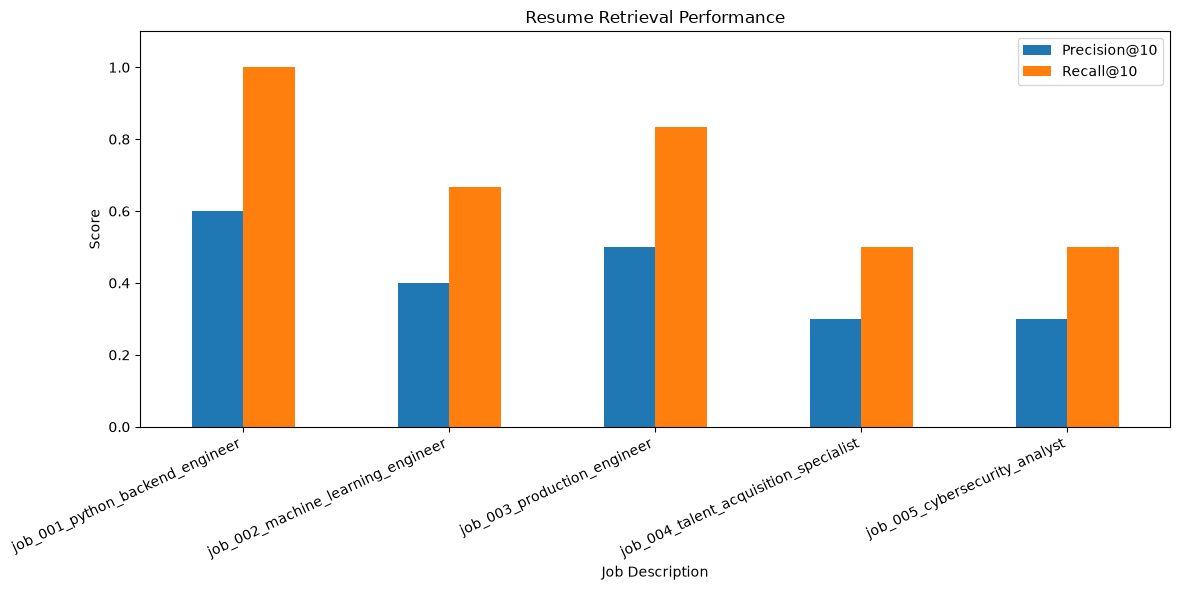

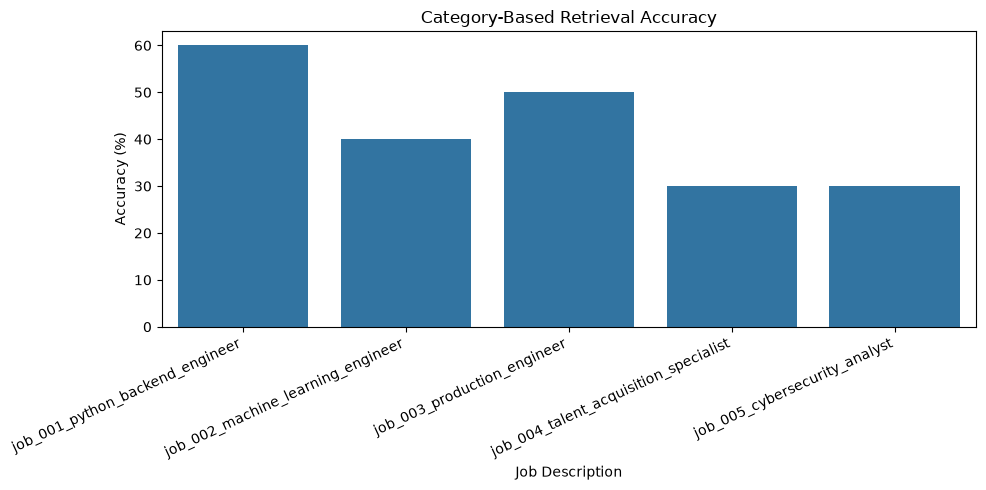

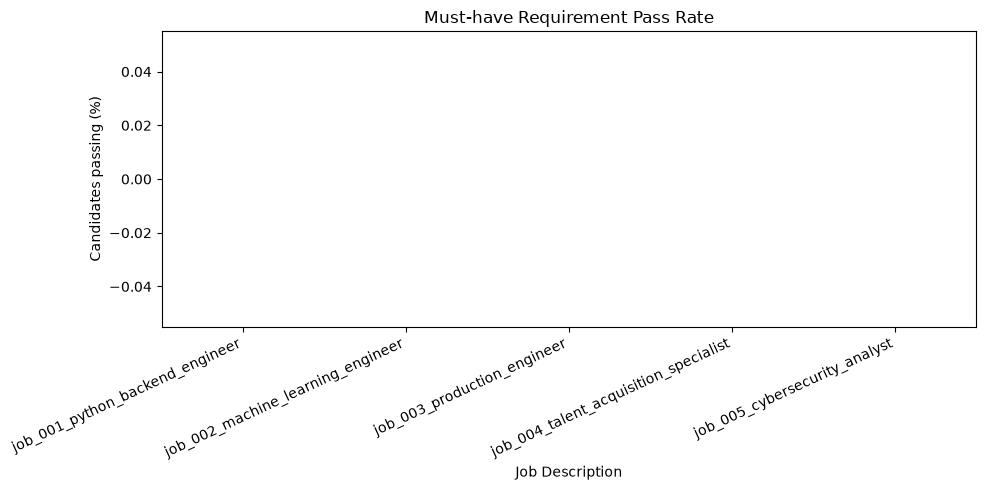

In [4]:

# Chart 1: Precision@10 and Recall@10
plt.figure(figsize=(12, 6))

evaluation_df.set_index("Job")[
    ["Precision@10", "Recall@10"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Resume Retrieval Performance")
plt.ylabel("Score")
plt.xlabel("Job Description")
plt.ylim(0, 1.1)
plt.xticks(rotation=25, ha="right")
plt.legend()
plt.tight_layout()
plt.show()


# Chart 2: Category Accuracy
plt.figure(figsize=(10, 5))

sns.barplot(
    data=evaluation_df,
    x="Job",
    y="Category Accuracy (%)"
)

plt.title("Category-Based Retrieval Accuracy")
plt.ylabel("Accuracy (%)")
plt.xlabel("Job Description")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


# Chart 3: Must-have pass rate
plt.figure(figsize=(10, 5))

sns.barplot(
    data=evaluation_df,
    x="Job",
    y="Must-have Pass Rate (%)"
)

plt.title("Must-have Requirement Pass Rate")
plt.ylabel("Candidates passing (%)")
plt.xlabel("Job Description")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()



In [5]:

# Save evaluation metrics
report_path = OUTPUT_DIR / "evaluation_metrics.csv"

evaluation_df.to_csv(report_path, index=False)

print("Evaluation saved successfully:")
print(report_path)

print("\nAverage Precision@10:",
      round(evaluation_df["Precision@10"].mean(), 3))

print("Average Recall@10:",
      round(evaluation_df["Recall@10"].mean(), 3))

print("Average Category Accuracy:",
      round(evaluation_df["Category Accuracy (%)"].mean(), 2), "%")


Evaluation saved successfully:
C:\Resume-RAG\outputs\evaluation_metrics.csv

Average Precision@10: 0.42
Average Recall@10: 0.7
Average Category Accuracy: 42.0 %


In [6]:

# Inspect latency information stored in matching JSON files

latency_results = []

for file in result_files:
    with open(file, "r", encoding="utf-8") as f:
        data = json.load(f)

    print("\nFile:", file.name)
    print("Available JSON keys:", list(data.keys()))

    # Find latency field if available
    latency = None

    for key in data:
        if "latency" in key.lower() or "time" in key.lower():
            latency = data[key]
            break

    latency_results.append({
        "Job": file.stem.replace("-results", ""),
        "Latency (seconds)": latency
    })

latency_df = pd.DataFrame(latency_results)
latency_df



File: job_001_python_backend_engineer-results.json
Available JSON keys: ['job_description', 'detected_required_experience', 'detected_must_have_skills', 'detected_job_skills', 'retrieved_candidates', 'top_matches', 'latency_seconds']

File: job_002_machine_learning_engineer-results.json
Available JSON keys: ['job_description', 'detected_required_experience', 'detected_must_have_skills', 'detected_job_skills', 'retrieved_candidates', 'top_matches', 'latency_seconds']

File: job_003_production_engineer-results.json
Available JSON keys: ['job_description', 'detected_required_experience', 'detected_must_have_skills', 'detected_job_skills', 'retrieved_candidates', 'top_matches', 'latency_seconds']

File: job_004_talent_acquisition_specialist-results.json
Available JSON keys: ['job_description', 'detected_required_experience', 'detected_must_have_skills', 'detected_job_skills', 'retrieved_candidates', 'top_matches', 'latency_seconds']

File: job_005_cybersecurity_analyst-results.json
Availa

,Job,Latency (seconds)
0,job_001_python_backend_engineer,0.1496
1,job_002_machine_learning_engineer,0.0473
2,job_003_production_engineer,0.0442
3,job_004_talent_acquisition_specialist,0.0446
4,job_005_cybersecurity_analyst,0.0428


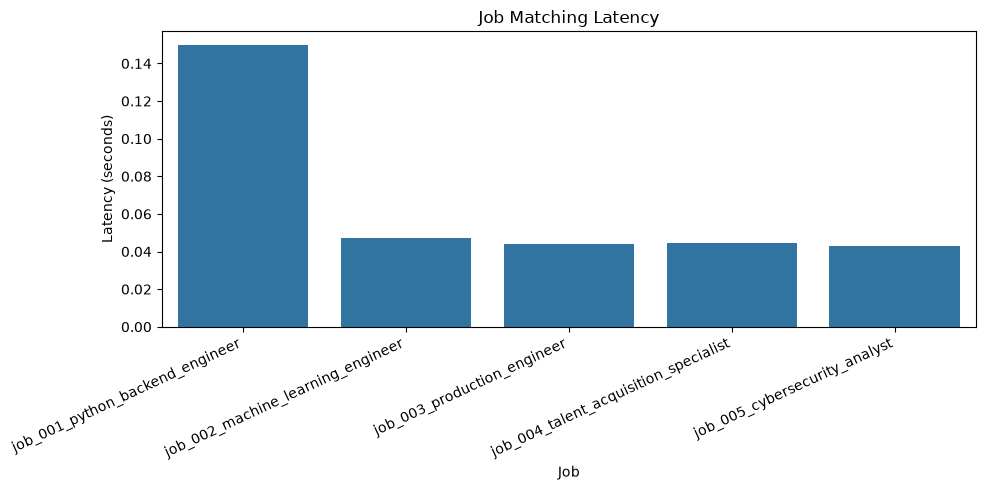

Average latency: 0.0657 seconds


In [7]:

# Plot latency where available
valid_latency = latency_df.dropna().copy()

if not valid_latency.empty:
    valid_latency["Latency (seconds)"] = pd.to_numeric(
        valid_latency["Latency (seconds)"],
        errors="coerce"
    )
    valid_latency = valid_latency.dropna()

    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=valid_latency,
        x="Job",
        y="Latency (seconds)"
    )
    plt.title("Job Matching Latency")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

    print("Average latency:",
          round(valid_latency["Latency (seconds)"].mean(), 4),
          "seconds")
else:
    print("No latency field found in the JSON files.")
    print("We will measure latency directly from the matcher next.")


In [8]:

# Combine retrieval metrics and latency

final_report = evaluation_df.merge(
    latency_df,
    on="Job",
    how="left"
)

final_report.to_csv(
    OUTPUT_DIR / "final_evaluation_report.csv",
    index=False
)

print("FINAL RESUME RAG EVALUATION")
print("=" * 50)
display(final_report)

print("\nOVERALL PERFORMANCE")
print("Average Precision@10:",
      round(final_report["Precision@10"].mean(), 3))

print("Average Recall@10:",
      round(final_report["Recall@10"].mean(), 3))

print("Average latency:",
      round(final_report["Latency (seconds)"].mean(), 4),
      "seconds")

print("\nReport saved successfully!")



FINAL RESUME RAG EVALUATION


,Job,Expected Category,Relevant Candidates,Precision@10,Recall@10,Category Accuracy (%),Must-have Pass Rate (%),Latency (seconds)
0,job_001_python_backend_engineer,Software Engineering,6,0.6,1.000,60.0,0.0,0.1496
1,job_002_machine_learning_engineer,Data Science,4,0.4,0.667,40.0,0.0,0.0473
2,job_003_production_engineer,Mechanical Engineering,5,0.5,0.833,50.0,0.0,0.0442
3,job_004_talent_acquisition_specialist,Human Resources,3,0.3,0.500,30.0,0.0,0.0446
4,job_005_cybersecurity_analyst,Other Technical,3,0.3,0.500,30.0,0.0,0.0428



OVERALL PERFORMANCE
Average Precision@10: 0.42
Average Recall@10: 0.7
Average latency: 0.0657 seconds

Report saved successfully!


In [9]:

# Rank job descriptions by retrieval performance

performance_review = final_report[
    [
        "Job",
        "Precision@10",
        "Recall@10",
        "Category Accuracy (%)",
        "Must-have Pass Rate (%)",
        "Latency (seconds)"
    ]
].sort_values(
    by="Precision@10",
    ascending=True
)

display(performance_review)

print("\nLowest-performing job:")
print(performance_review.iloc[0]["Job"])

print("\nHighest-performing job:")
print(performance_review.iloc[-1]["Job"])


,Job,Precision@10,Recall@10,Category Accuracy (%),Must-have Pass Rate (%),Latency (seconds)
3,job_004_talent_acquisition_specialist,0.3,0.500,30.0,0.0,0.0446
4,job_005_cybersecurity_analyst,0.3,0.500,30.0,0.0,0.0428
1,job_002_machine_learning_engineer,0.4,0.667,40.0,0.0,0.0473
2,job_003_production_engineer,0.5,0.833,50.0,0.0,0.0442
0,job_001_python_backend_engineer,0.6,1.000,60.0,0.0,0.1496



Lowest-performing job:
job_004_talent_acquisition_specialist

Highest-performing job:
job_001_python_backend_engineer


In [10]:

# Inspect actual candidate fields
sample_file = OUTPUT_DIR / "job_005_cybersecurity_analyst-results.json"

with open(sample_file, "r", encoding="utf-8") as f:
    sample_data = json.load(f)

print("Top-level keys:")
print(list(sample_data.keys()))

print("\nFirst candidate:")
print(json.dumps(sample_data["top_matches"][0], indent=2))


Top-level keys:
['job_description', 'detected_required_experience', 'detected_must_have_skills', 'detected_job_skills', 'retrieved_candidates', 'top_matches', 'latency_seconds']

First candidate:
{
  "candidate_name": "Pranav Kulkarni",
  "resume_path": "resumes/resume_026.pdf",
  "match_score": 83.17,
  "matched_skills": [
    "python",
    "linux",
    "splunk",
    "incident response",
    "siem"
  ],
  "relevant_excerpts": [
    "Cybersecurity Analyst | Sample Organization | 2022\u20132026 Investigated security alerts, documented incidents and helped improve detection rules.",
    "cybersecurity analyst with 4 years of experience. Background in other technical with practical experience delivering team and business outcomes.",
    "SIEM, Splunk, Python, Linux, Incident Response, Vulnerability Assessment"
  ],
  "matched_sections": [
    "education",
    "experience",
    "general",
    "skills",
    "summary"
  ],
  "experience_years": 4.0,
  "education": "B.Tech Information Securit

In [11]:

# Correct must-have evaluation

must_have_results = []

for file in result_files:
    with open(file, "r", encoding="utf-8") as f:
        data = json.load(f)

    matches = data["top_matches"][:10]

    passed = sum(
        1 for candidate in matches
        if candidate.get("must_have_check", {}).get("passed", False)
    )

    total = len(matches)

    pass_rate = (passed / total * 100) if total else 0

    must_have_results.append({
        "Job": file.stem.replace("-results", ""),
        "Must-have Passed": passed,
        "Candidates Evaluated": total,
        "Must-have Pass Rate (%)": round(pass_rate, 2),
        "Detected Requirements": ", ".join(
            data.get("detected_must_have_skills", [])
        )
    })

must_have_df = pd.DataFrame(must_have_results)

display(must_have_df)



,Job,Must-have Passed,Candidates Evaluated,Must-have Pass Rate (%),Detected Requirements
0,job_001_python_backend_engineer,0,10,0.0,"python, django, flask, fastapi, docker, postgr..."
1,job_002_machine_learning_engineer,0,10,0.0,"python, machine learning, tensorflow, pytorch"
2,job_003_production_engineer,1,10,10.0,"six sigma, lean manufacturing, root cause anal..."
3,job_004_talent_acquisition_specialist,0,10,0.0,"recruitment, ats"
4,job_005_cybersecurity_analyst,1,10,10.0,"linux, incident response, siem"


In [12]:

# Replace incorrect must-have pass rates
final_report = (
    final_report.drop(columns=["Must-have Pass Rate (%)"])
    .merge(
        must_have_df[
            ["Job", "Must-have Pass Rate (%)"]
        ],
        on="Job",
        how="left"
    )
)

final_report.to_csv(
    OUTPUT_DIR / "final_evaluation_report.csv",
    index=False
)

display(final_report)

print("Updated final evaluation report saved.")


,Job,Expected Category,Relevant Candidates,Precision@10,Recall@10,Category Accuracy (%),Latency (seconds),Must-have Pass Rate (%)
0,job_001_python_backend_engineer,Software Engineering,6,0.6,1.000,60.0,0.1496,0.0
1,job_002_machine_learning_engineer,Data Science,4,0.4,0.667,40.0,0.0473,0.0
2,job_003_production_engineer,Mechanical Engineering,5,0.5,0.833,50.0,0.0442,10.0
3,job_004_talent_acquisition_specialist,Human Resources,3,0.3,0.500,30.0,0.0446,0.0
4,job_005_cybersecurity_analyst,Other Technical,3,0.3,0.500,30.0,0.0428,10.0


Updated final evaluation report saved.


In [13]:

# Detailed retrieval diagnostics

diagnostics = []

for file in result_files:
    with open(file, "r", encoding="utf-8") as f:
        data = json.load(f)

    matches = data.get("top_matches", [])

    passed = [
        c for c in matches
        if c.get("must_have_check", {}).get("passed", False)
    ]

    diagnostics.append({
        "Job": file.stem.replace("-results", ""),
        "Retrieved candidates": data.get("retrieved_candidates", 0),
        "Top 10 candidates": len(matches),
        "Unique candidates": len({
            c.get("candidate_name") for c in matches
        }),
        "Must-have passed": len(passed),
        "Must-have failed": len(matches) - len(passed),
        "Detected must-have skills": ", ".join(
            data.get("detected_must_have_skills", [])
        )
    })

diagnostics_df = pd.DataFrame(diagnostics)
display(diagnostics_df)


,Job,Retrieved candidates,Top 10 candidates,Unique candidates,Must-have passed,Must-have failed,Detected must-have skills
0,job_001_python_backend_engineer,30,10,10,0,10,"python, django, flask, fastapi, docker, postgr..."
1,job_002_machine_learning_engineer,30,10,10,0,10,"python, machine learning, tensorflow, pytorch"
2,job_003_production_engineer,30,10,10,1,9,"six sigma, lean manufacturing, root cause anal..."
3,job_004_talent_acquisition_specialist,30,10,10,0,10,"recruitment, ats"
4,job_005_cybersecurity_analyst,30,10,10,1,9,"linux, incident response, siem"
